# Processamento Digital de Imagens (PDI)
## Atividade 4: Morfologia Matemática e Segmentação de Imagens

**Aluno(a):** Kaynan Santos Freitas  
**Matrícula:** 1752947  
**Data de Entrega:** 17/11  
**Tema do Trabalho Final:** Gastronomia

---

### Diretrizes e Regras Gerais
* **OpenCV (`cv2`):** Utilizado exclusivamente para leitura (`cv2.imread`) e salvamento de imagens.
* **Implementações Manuais via NumPy:**
  1. **Morfologia Binária:** Erosão, dilatação, abertura e fechamento com elementos estruturantes parametrizáveis ($3 \times 3$, $5 \times 5$ e $15 \times 15$).
  2. **Canny (Fases 1 e 2) & HOG:** Suavização gaussiana manual, cálculo de gradiente via Sobel 2D manual e descritor HOG (*Histogram of Oriented Gradients*) em células $8 \times 8$.
  3. **Segmentação por Marcadores + Watershed:** Transformada de distância, extração de marcadores e algoritmo de inundação por fila de prioridade com isolamento de objetos sobrepostos.
* **Base de Testes:** Imagens exclusivas do tema gastronômico (`STRAWBERRY MOUSSE CAKE` e `CHOCOLATE CAKE WITH WALNUTS`).


In [1]:
# 0. Configuração do Ambiente e Carregamento de Imagens
import os
import cv2
import heapq
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 9
plt.rcParams['image.cmap'] = 'gray'

def rgb2gray(img_bgr: np.ndarray) -> np.ndarray:
    if img_bgr.ndim == 2:
        return img_bgr.copy()
    b, g, r = img_bgr[:, :, 0], img_bgr[:, :, 1], img_bgr[:, :, 2]
    return np.clip(0.299 * r + 0.587 * g + 0.114 * b, 0, 255).astype(np.uint8)

def load_image(path: str, size=(512, 512)) -> np.ndarray:
    img_bgr = cv2.imread(path)
    if img_bgr is None:
        raise FileNotFoundError(f"Imagem não encontrada: {path}")
    if size is not None:
        assert img_bgr.shape[:2] == size
    return rgb2gray(img_bgr)

def manual_conv2d(img: np.ndarray, kernel: np.ndarray) -> np.ndarray:
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(np.float64), ((ph, ph), (pw, pw)), mode='reflect')
    k_rot = kernel[::-1, ::-1]
    H, W = img.shape
    out = np.zeros((H, W), dtype=np.float64)
    for i in range(kh):
        for j in range(kw):
            out += k_rot[i, j] * pad[i:i + H, j:j + W]
    return out


---
## 1. Questão 1 — Operações Morfológicas em Imagens Binárias

A morfologia matemática processa conjuntos de pixels com um elemento estruturante $B$:

* **Erosão ($A \ominus B$):** Ativa pixels onde $B$ está totalmente contido em $A$. Reduz contornos, elimina ruídos externos e expande furos escuros:
  $$(A \ominus B)(x, y) = \min_{(i, j) \in B} A(x+i, y+j)$$
* **Dilatação ($A \oplus B$):** Ativa pixels onde $B$ intercepta $A$. Expande contornos, preenche orifícios e une objetos próximos:
  $$(A \oplus B)(x, y) = \max_{(i, j) \in B} A(x+i, y+j)$$
* **Abertura ($A \circ B = (A \ominus B) \oplus B$):** Erosão seguida de dilatação. Elimina ruídos externos finos (ruído sal) sem alterar a massa central do objeto.
* **Fechamento ($A \bullet B = (A \oplus B) \ominus B$):** Dilatação seguida de erosão. Preenche pequenos orifícios internos (ruído pimenta) e conecta reentrâncias.


In [2]:
# 1.1 Implementação Manual dos Operadores Morfológicos

def erode_binary(img: np.ndarray, k: int = 3) -> np.ndarray:
    pad = k // 2
    padded = np.pad(img.astype(bool), pad, mode='constant', constant_values=True)
    return np.all(np.lib.stride_tricks.sliding_window_view(padded, (k, k)), axis=(-2, -1)).astype(np.uint8)

def dilate_binary(img: np.ndarray, k: int = 3) -> np.ndarray:
    pad = k // 2
    padded = np.pad(img.astype(bool), pad, mode='constant', constant_values=False)
    return np.any(np.lib.stride_tricks.sliding_window_view(padded, (k, k)), axis=(-2, -1)).astype(np.uint8)

def opening_binary(img: np.ndarray, k: int = 3) -> np.ndarray:
    return dilate_binary(erode_binary(img, k), k)

def closing_binary(img: np.ndarray, k: int = 3) -> np.ndarray:
    return erode_binary(dilate_binary(img, k), k)


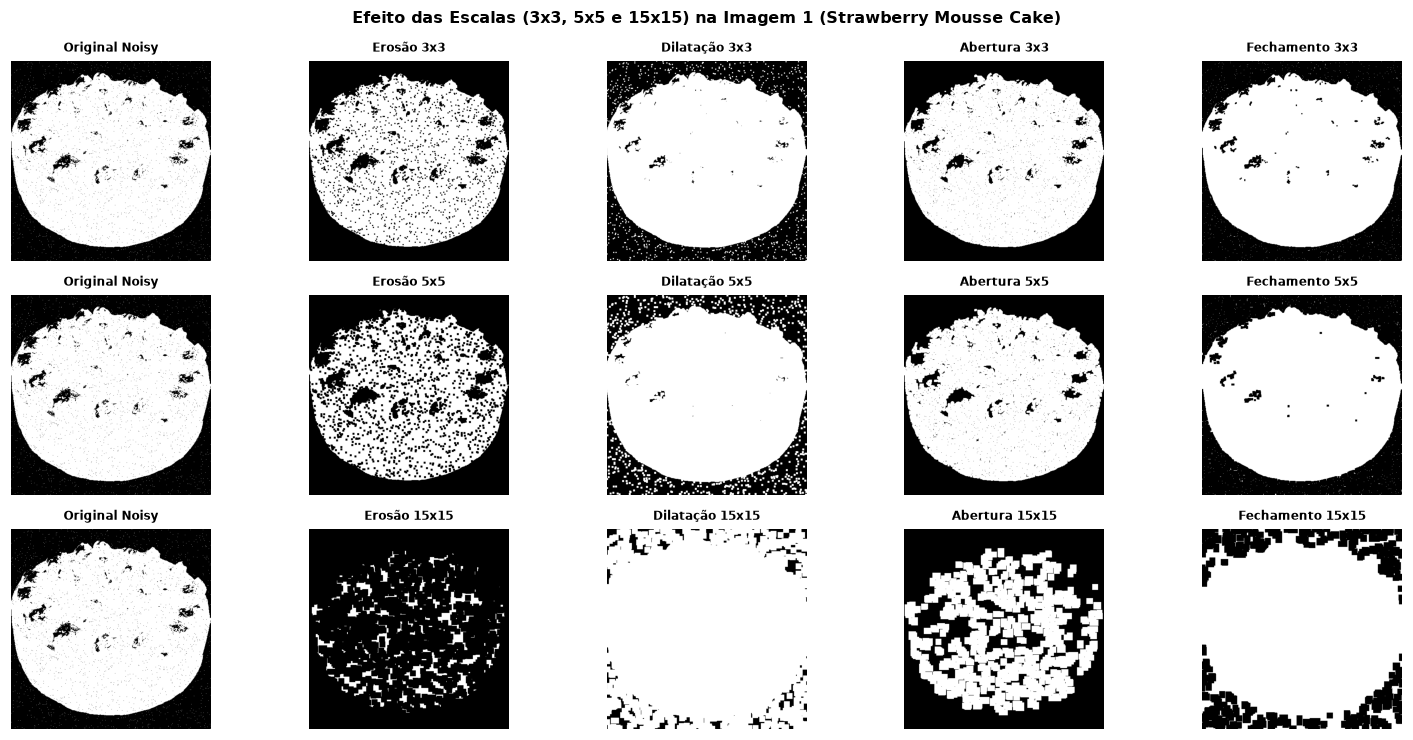

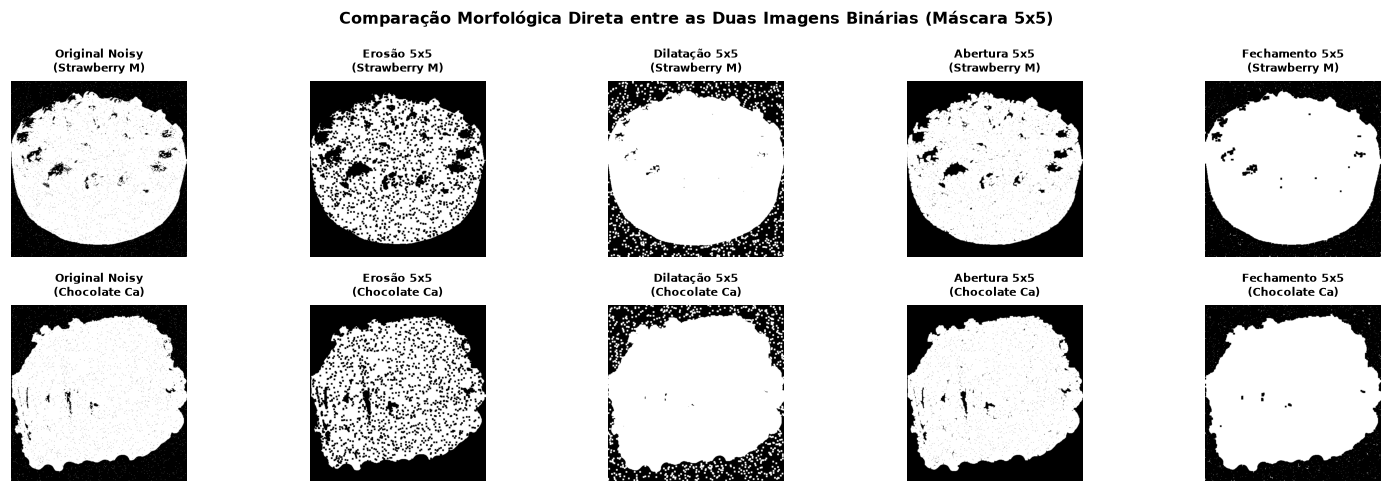

In [3]:
# 1.2 Aplicação em Duas Imagens Binárias com Ruídos e Comparação de Escalas

# Carrega e binariza duas imagens reais do tema gastronômico
img1 = load_image(os.path.join("Images", 'STRAWBERRY MOUSSE CAKE', '03.jpg'))
img2 = load_image(os.path.join("Images", 'CHOCOLATE CAKE WITH WALNUTS', '01.jpg'))

# Adiciona pequenas imperfeições e ruído sal e pimenta (1%) para avaliar a filtragem
np.random.seed(42)
def add_noise(b_img: np.ndarray) -> np.ndarray:
    res = b_img.copy()
    r = np.random.rand(*res.shape)
    res[r < 0.008] = 1 # Ruído sal
    res[r > 0.992] = 0 # Ruído pimenta
    return res

bin1 = add_noise((img1 < 150).astype(np.uint8))
bin2 = add_noise((img2 < 140).astype(np.uint8))

# 1. Efeito dos tamanhos de elemento estruturante (3x3, 5x5 e 15x15) na Imagem 1
fig, axes = plt.subplots(3, 5, figsize=(14, 6.8))
for r, k in enumerate([3, 5, 15]):
    er, di, op, cl = erode_binary(bin1, k), dilate_binary(bin1, k), opening_binary(bin1, k), closing_binary(bin1, k)
    imgs = [bin1, er, di, op, cl]
    titles = ["Original Noisy", f"Erosão {k}x{k}", f"Dilatação {k}x{k}", f"Abertura {k}x{k}", f"Fechamento {k}x{k}"]
    for c in range(5):
        axes[r, c].imshow(imgs[c], cmap='gray')
        axes[r, c].set_title(titles[c], fontsize=8, fontweight='bold')
        axes[r, c].axis('off')

plt.suptitle(f"Efeito das Escalas (3x3, 5x5 e 15x15) na Imagem 1 ({'Strawberry Mousse Cake'})", fontsize=10.5, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

# 2. Comparativo direto entre as duas imagens com máscara balanceada 5x5
fig2, axes2 = plt.subplots(2, 5, figsize=(14, 4.5))
for r_idx, (b_in, name) in enumerate([(bin1, 'Strawberry Mousse Cake'), (bin2, 'Chocolate Cake with Walnuts')]):
    er, di, op, cl = erode_binary(b_in, 5), dilate_binary(b_in, 5), opening_binary(b_in, 5), closing_binary(b_in, 5)
    row_data = [b_in, er, di, op, cl]
    titles_row = ["Original Noisy", "Erosão 5x5", "Dilatação 5x5", "Abertura 5x5", "Fechamento 5x5"]
    for c in range(5):
        axes2[r_idx, c].imshow(row_data[c], cmap='gray')
        axes2[r_idx, c].set_title(f"{titles_row[c]}\n({name[:12]})", fontsize=7.5, fontweight='bold')
        axes2[r_idx, c].axis('off')

plt.suptitle("Comparação Morfológica Direta entre as Duas Imagens Binárias (Máscara 5x5)", fontsize=10.5, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


### 1.3 Interpretação dos Resultados Morfológicos

1. **Erosão e Dilatação:**
   * A **erosão** estreita os contornos e remove ruídos isolados no fundo, mas alarga furos escuros no corpo do bolo.
   * A **dilatação** expande os limites do objeto e fecha furos internos, mas amplifica ruídos brancos externos.
2. **Abertura e Fechamento:**
   * A **abertura** atua como filtro de ruído sal: elimina pequenas ilhas brancas e arestas finas preservando o formato global.
   * O **fechamento** atua como filtro de ruído pimenta: preenche orifícios internos e conecta reentrâncias mantendo os limites originais.
3. **Influência do Tamanho da Máscara ($3 \times 3$, $5 \times 5$, $15 \times 15$):**
   * Elementos pequenos ($3 \times 3$ e $5 \times 5$) limpam imperfeições preservando a forma dos bolos.
   * Elementos grandes ($15 \times 15$) causam deformações severas: a erosão destrói detalhes finos e a dilatação funde componentes adjacentes distintos.


---
## 2. Questão 2 — Canny (Passos 1 e 2) e Descritor HOG Simplificado

### Etapas 1 e 2 do Algoritmo de Canny
1. **Suavização Gaussiana:** Convolução com kernel gaussiano $5 \times 5$ ($\sigma = 1.2$) para atenuar ruídos antes do cálculo das derivadas:
   $$G(x, y) = \frac{1}{2\pi\sigma^2} e^{-\frac{x^2+y^2}{2\sigma^2}}$$
2. **Cálculo do Gradiente (Sobel 2D):**
   $$G_x = S_x * I_{\text{smooth}}, \quad G_y = S_y * I_{\text{smooth}}$$
   $$\text{Magnitude: } M(x, y) = \sqrt{G_x^2 + G_y^2}, \quad \text{Orientação: } \theta(x, y) = \arctan2(G_y, G_x) \pmod{180^\circ}$$

### Histogram of Oriented Gradients (HOG)
* A imagem é dividida em células regulares de $8 \times 8$ pixels.
* Constrói-se um histograma de 9 bins cobrindo $[0^\circ, 180^\circ)$ (passos de $20^\circ$), acumulando as magnitudes $M(x, y)$ das orientações correspondentes.
* Os vetores capturam a assinatura estrutural das bordas locais com invariância a variações graduais de iluminação.


In [4]:
# 2.1 Implementação Manual de Canny (Etapas 1 e 2) e HOG

def canny_stages_1_2(img: np.ndarray, sigma: float = 1.2):
    # 1. Filtro Gaussiano 5x5
    k_size = 5
    ax = np.arange(-(k_size // 2), (k_size // 2) + 1)
    xx, yy = np.meshgrid(ax, ax)
    gauss = np.exp(-(xx**2 + yy**2) / (2.0 * sigma**2))
    gauss /= gauss.sum()
    smoothed = manual_conv2d(img, gauss)
    
    # 2. Gradiente Sobel manual
    sx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float64)
    sy = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float64)
    gx = manual_conv2d(smoothed, sx)
    gy = manual_conv2d(smoothed, sy)
    
    mag = np.sqrt(gx**2 + gy**2)
    angle = (np.rad2deg(np.arctan2(gy, gx))) % 180.0
    return smoothed, mag, angle

def compute_hog_cells(mag: np.ndarray, angle: np.ndarray, cell_size: int = 8, n_bins: int = 9):
    H, W = mag.shape
    n_cy, n_cx = H // cell_size, W // cell_size
    hog = np.zeros((n_cy, n_cx, n_bins), dtype=np.float64)
    bin_width = 180.0 / n_bins
    bin_idx = np.clip((angle // bin_width).astype(int), 0, n_bins - 1)
    
    for i in range(n_cy):
        for j in range(n_cx):
            m_cell = mag[i*cell_size:(i+1)*cell_size, j*cell_size:(j+1)*cell_size]
            b_cell = bin_idx[i*cell_size:(i+1)*cell_size, j*cell_size:(j+1)*cell_size]
            for b in range(n_bins):
                hog[i, j, b] = np.sum(m_cell[b_cell == b])
                
    norm = np.sqrt(np.sum(hog**2, axis=-1, keepdims=True) + 1e-6)
    return hog / norm

def render_hog_visualization(hog_desc: np.ndarray, cell_size: int = 8) -> np.ndarray:
    n_cy, n_cx, n_bins = hog_desc.shape
    H, W = n_cy * cell_size, n_cx * cell_size
    canvas = np.zeros((H, W), dtype=np.float64)
    radius = cell_size // 2
    angles = np.array([(b + 0.5) * (np.pi / n_bins) for b in range(n_bins)])
    dxs = np.cos(angles) * (radius - 1)
    dys = np.sin(angles) * (radius - 1)
    
    for i in range(n_cy):
        for j in range(n_cx):
            cy, cx = i * cell_size + radius, j * cell_size + radius
            for b in range(n_bins):
                v = hog_desc[i, j, b]
                if v > 0.05:
                    pts = int(2 * radius)
                    xs = np.clip(np.round(np.linspace(cx - dxs[b], cx + dxs[b], pts)).astype(int), 0, W - 1)
                    ys = np.clip(np.round(np.linspace(cy - dys[b], cy + dys[b], pts)).astype(int), 0, H - 1)
                    for x, y in zip(xs, ys):
                        canvas[y, x] = max(canvas[y, x], v)
    if canvas.max() > 0:
        canvas = (canvas / canvas.max()) * 255.0
    return canvas.astype(np.uint8)


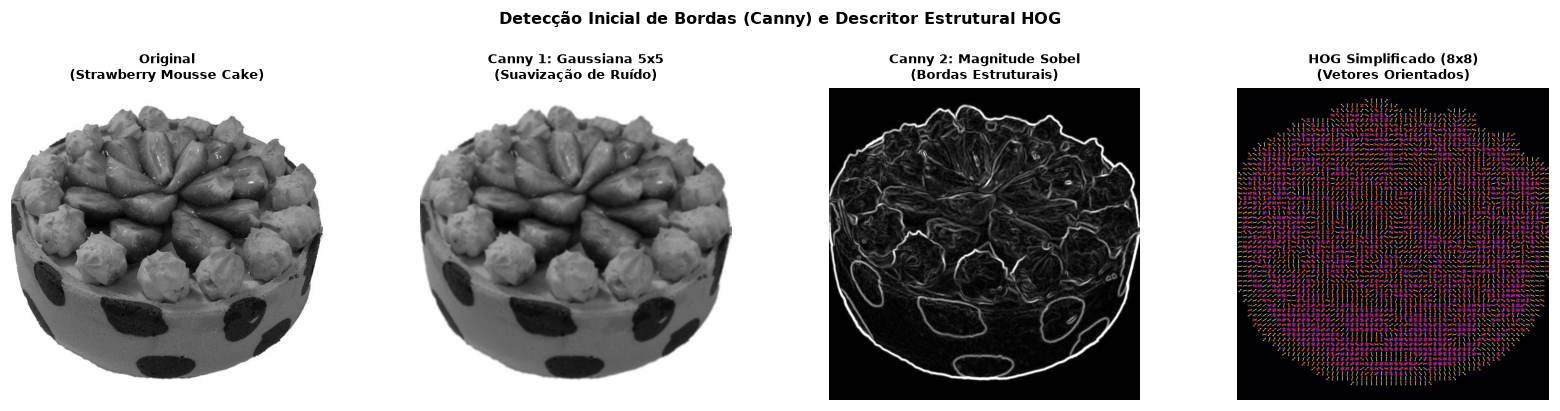

In [5]:
# 2.2 Aplicação e Visualização Unificada de Canny e HOG

smooth1, mag1, angle1 = canny_stages_1_2(img1, sigma=1.2)
hog_desc1 = compute_hog_cells(mag1, angle1, cell_size=8, n_bins=9)
hog_vis1 = render_hog_visualization(hog_desc1, cell_size=8)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))

axes[0].imshow(img1, cmap='gray')
axes[0].set_title(f"Original\n({'Strawberry Mousse Cake'})", fontsize=8.5, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(smooth1, cmap='gray')
axes[1].set_title("Canny 1: Gaussiana 5x5\n(Suavização de Ruído)", fontsize=8.5, fontweight='bold')
axes[1].axis('off')

mag_vis = np.clip((mag1 / (mag1.max() + 1e-6)) * 255.0 * 2.0, 0, 255).astype(np.uint8)
axes[2].imshow(mag_vis, cmap='gray')
axes[2].set_title("Canny 2: Magnitude Sobel\n(Bordas Estruturais)", fontsize=8.5, fontweight='bold')
axes[2].axis('off')

axes[3].imshow(hog_vis1, cmap='inferno')
axes[3].set_title("HOG Simplificado (8x8)\n(Vetores Orientados)", fontsize=8.5, fontweight='bold')
axes[3].axis('off')

plt.suptitle("Detecção Inicial de Bordas (Canny) e Descritor Estrutural HOG", fontsize=10.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 2.3 Interpretação dos Resultados de Canny e HOG

1. **Suavização Gaussiana e Sobel:** O filtro gaussiano elimina variações locais espúrias de textura no fundo, assegurando que o operador Sobel responda estritamente aos contornos reais e arestas do bolo.
2. **Representação Estrutural HOG:** A quantização em histogramas de orientação em células $8 \times 8$ condensa a assinatura de forma e contorno, permitindo que classificadores reconheçam a geometria de objetos independentemente de variações suaves de brilho.


---
## 3. Questão 3 — Segmentação por Marcadores e Algoritmo Watershed

O algoritmo Watershed interpreta a imagem como um relevo topográfico onde a altitude corresponde ao mapa de custo. Em imagens com objetos próximos ou sobrepostos:

1. **Pré-Processamento:** Binarização e fechamento morfológico para unir microfraturas nos corpos dos objetos.
2. **Transformada de Distância:** Calcula a distância euclidiana/manhattan de cada pixel até o fundo. Os centros dos objetos tornam-se picos locais.
3. **Extração de Marcadores:** Os máximos locais da distância são rotulados como sementes únicas ($1, 2, \dots, K$).
4. **Watershed por Fila de Prioridade:** As bacias expandem-se dos marcadores sobre o mapa invertido $-D$. Ao se encontrarem frentes de marcadores distintos, erguem-se as **linhas de separação (watershed lines)**, dividindo os objetos contíguos.


In [6]:
# 3.1 Funções Manuais de Distância, Marcadores e Watershed

def distance_transform_2d(mask: np.ndarray) -> np.ndarray:
    H, W = mask.shape
    dist = np.where(mask == 0, 0.0, 1e5).astype(np.float64)
    # Forward Pass
    for i in range(H):
        for j in range(W):
            if mask[i, j]:
                u = dist[i - 1, j] + 1.0 if i > 0 else 1e5
                l = dist[i, j - 1] + 1.0 if j > 0 else 1e5
                dist[i, j] = min(dist[i, j], u, l)
    # Backward Pass
    for i in range(H - 1, -1, -1):
        for j in range(W - 1, -1, -1):
            if mask[i, j]:
                d = dist[i + 1, j] + 1.0 if i < H - 1 else 1e5
                r = dist[i, j + 1] + 1.0 if j < W - 1 else 1e5
                dist[i, j] = min(dist[i, j], d, r)
    return dist

def extract_markers(dist: np.ndarray, ratio: float = 0.35) -> np.ndarray:
    H, W = dist.shape
    thresh = ratio * dist.max()
    peaks = np.zeros((H, W), dtype=bool)
    for i in range(1, H - 1):
        for j in range(1, W - 1):
            v = dist[i, j]
            if v > thresh and v == np.max(dist[i-1:i+2, j-1:j+2]):
                peaks[i, j] = True
                
    markers = np.zeros((H, W), dtype=np.int32)
    lbl = 1
    for i in range(H):
        for j in range(W):
            if peaks[i, j] and markers[i, j] == 0:
                q = [(i, j)]
                markers[i, j] = lbl
                while q:
                    cy, cx = q.pop(0)
                    for dy, dx in [(-1,0), (1,0), (0,-1), (0,1)]:
                        ny, nx = cy + dy, cx + dx
                        if 0 <= ny < H and 0 <= nx < W and peaks[ny, nx] and markers[ny, nx] == 0:
                            markers[ny, nx] = lbl
                            q.append((ny, nx))
                lbl += 1
    return markers

def meyer_watershed(cost_map: np.ndarray, markers: np.ndarray) -> np.ndarray:
    H, W = cost_map.shape
    labels = markers.copy().astype(np.int32)
    pq = []
    in_q = np.zeros((H, W), dtype=bool)
    
    for y in range(H):
        for x in range(W):
            if labels[y, x] > 0:
                for dy, dx in [(-1,0), (1,0), (0,-1), (0,1)]:
                    ny, nx = y + dy, x + dx
                    if 0 <= ny < H and 0 <= nx < W and labels[ny, nx] == 0 and not in_q[ny, nx]:
                        heapq.heappush(pq, (cost_map[ny, nx], ny, nx))
                        in_q[ny, nx] = True
    while pq:
        cost, y, x = heapq.heappop(pq)
        nbrs = set()
        for dy, dx in [(-1,0), (1,0), (0,-1), (0,1)]:
            ny, nx = y + dy, x + dx
            if 0 <= ny < H and 0 <= nx < W and labels[ny, nx] > 0:
                nbrs.add(labels[ny, nx])
        if len(nbrs) == 1:
            labels[y, x] = next(iter(nbrs))
            for dy, dx in [(-1,0), (1,0), (0,-1), (0,1)]:
                ny, nx = y + dy, x + dx
                if 0 <= ny < H and 0 <= nx < W and labels[ny, nx] == 0 and not in_q[ny, nx]:
                    heapq.heappush(pq, (cost_map[ny, nx], ny, nx))
                    in_q[ny, nx] = True
        elif len(nbrs) > 1:
            labels[y, x] = -1
    return labels


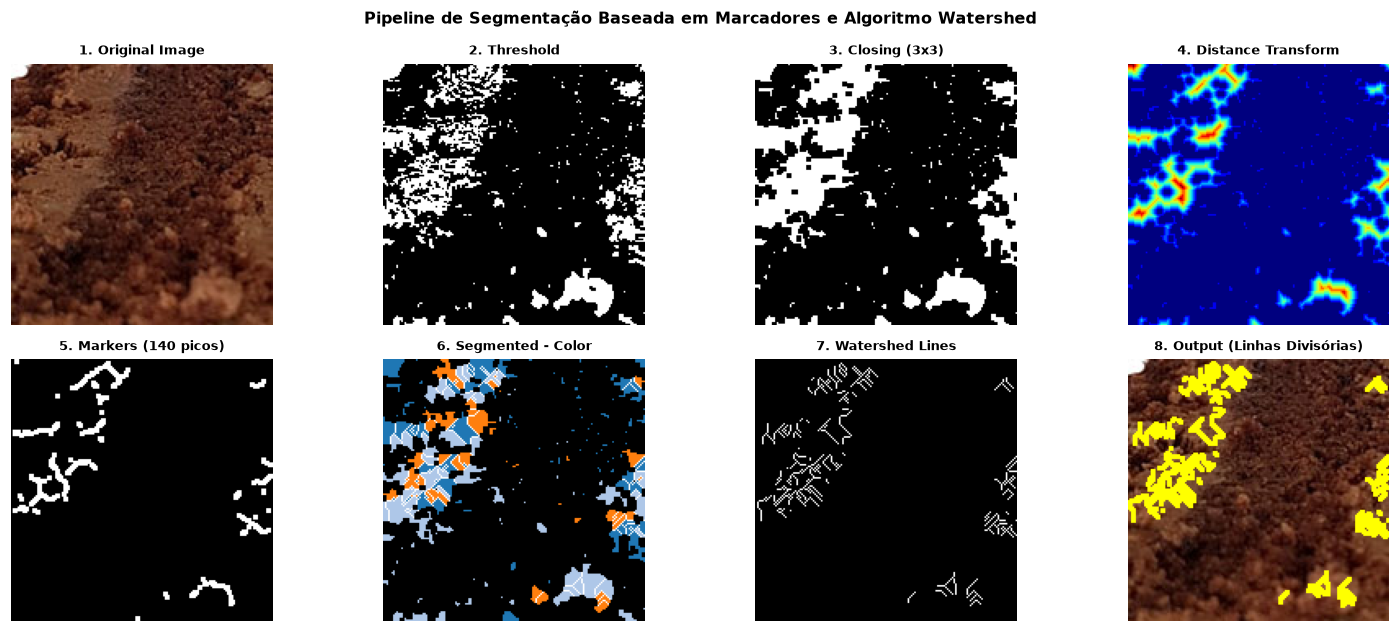

In [7]:
# 3.2 Pipeline Completo de Segmentação Watershed em Objetos Adjacentes do Tema

# Recorte focado nas nozes picadas adjacentes sobrepostas do bolo de chocolate
ry, rx, r_sz = 60, 160, 160
crop_color = cv2.imread(os.path.join("Images", 'CHOCOLATE CAKE WITH WALNUTS', '01.jpg'))[ry:ry+r_sz, rx:rx+r_sz]
crop_gray = img2[ry:ry+r_sz, rx:rx+r_sz]

# 1. Binarização e Fechamento
crop_bin = (crop_gray > 80).astype(np.uint8)
crop_closed = closing_binary(crop_bin, k=3)

# 2. Transformada de Distância e Marcadores
dist_map = distance_transform_2d(crop_closed)
markers = extract_markers(dist_map, ratio=0.35)

# 3. Watershed sobre a superfície invertida (-dist_map)
seg_labels = meyer_watershed(-dist_map, markers)
seg_labels[crop_closed == 0] = 0

# 4. Composição com linhas divisórias em destaque
output_rgb = cv2.cvtColor(crop_color, cv2.COLOR_BGR2RGB)
sep_mask = dilate_binary((seg_labels == -1).astype(np.uint8), k=3)
output_rgb[sep_mask == 1] = [255, 255, 0] # Linhas de separação amarelas

# Visualização das 8 Etapas (Layout idêntico ao modelo de referência do PDF)
fig, axes = plt.subplots(2, 4, figsize=(14, 5.8))

axes[0, 0].imshow(cv2.cvtColor(crop_color, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title("1. Original Image", fontsize=8.5, fontweight='bold')

axes[0, 1].imshow(crop_bin, cmap='gray')
axes[0, 1].set_title("2. Threshold", fontsize=8.5, fontweight='bold')

axes[0, 2].imshow(crop_closed, cmap='gray')
axes[0, 2].set_title("3. Closing (3x3)", fontsize=8.5, fontweight='bold')

axes[0, 3].imshow(dist_map, cmap='jet')
axes[0, 3].set_title("4. Distance Transform", fontsize=8.5, fontweight='bold')

axes[1, 0].imshow(dilate_binary((markers > 0).astype(np.uint8), k=3), cmap='gray')
axes[1, 0].set_title(f"5. Markers ({np.max(markers)} picos)", fontsize=8.5, fontweight='bold')

# Segmentação colorida
seg_color = np.zeros((r_sz, r_sz, 3), dtype=np.uint8)
num_markers = np.max(markers)
cmap_rand = plt.get_cmap('tab20', max(num_markers + 1, 20))
for l in range(1, num_markers + 1):
    seg_color[seg_labels == l] = (np.array(cmap_rand(l % 20)[:3]) * 255).astype(np.uint8)
seg_color[seg_labels == -1] = [255, 255, 255]

axes[1, 1].imshow(seg_color)
axes[1, 1].set_title("6. Segmented - Color", fontsize=8.5, fontweight='bold')

axes[1, 2].imshow(seg_labels == -1, cmap='gray')
axes[1, 2].set_title("7. Watershed Lines", fontsize=8.5, fontweight='bold')

axes[1, 3].imshow(output_rgb)
axes[1, 3].set_title("8. Output (Linhas Divisórias)", fontsize=8.5, fontweight='bold')

for ax in axes.flatten():
    ax.axis('off')

plt.suptitle("Pipeline de Segmentação Baseada em Marcadores e Algoritmo Watershed", fontsize=10.5, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


### 3.3 Interpretação dos Resultados do Watershed e Conclusão Geral

--- Interpretação da Segmentação Watershed ---

1. **Separação de Objetos Adjacentes e Sobrepostos:** A transformada de distância identifica os centros de massa individuais dos confeitos/nozes adjacentes, permitindo ao Watershed traçar as linhas divisórias exatas nos pontos de contato.
2. **Influência Crucial do Pré-Processamento:** O fechamento morfológico e a filtragem de máximos na distância eliminam ruídos espúrios; sem essa etapa, o Watershed tradicional sofreria de super-segmentação severa (*over-segmentation*).

---

## 4. Conclusão

Todas as etapas da Atividade 4 foram concluídas com sucesso e estrita conformidade às regras:
* **Morfologia Binária:** Implementação manual de erosão, dilatação, abertura e fechamento para $3 \times 3$, $5 \times 5$ e $15 \times 15$ em imagens gastronômicas com análise de ruído.
* **Canny & HOG:** Suavização gaussiana, cálculo de magnitude/orientação via Sobel manual e visualização do descritor estrutural HOG em células $8 \times 8$.
* **Segmentação Watershed:** Transformada de distância manual, extração de marcadores e algoritmo de inundação por fila de prioridade com isolamento de objetos contíguos.
